# ПР №5 — Классификация и выбор порога, уровень B

Данные scikit-learn Breast Cancer Wisconsin. **Положительный класс 1 = злокачественная опухоль**, 0 = доброкачественная. Это только учебное упражнение; модель не предназначена для медицинских решений.

**Важное ограничение:** преподаватель не приложил стоимость ошибок. Для демонстрации принимаем **FN = 5 условных единиц, FP = 1**. Не следует выдавать это допущение за предоставленное преподавателем.

In [1]:
from pathlib import Path
import numpy as np,pandas as pd,matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (roc_curve,precision_recall_curve,roc_auc_score,average_precision_score,confusion_matrix,accuracy_score,precision_score,recall_score,f1_score,ConfusionMatrixDisplay)
FIG=Path('../figures');FIG.mkdir(exist_ok=True)
df=pd.read_csv('../data/breast_cancer.csv')
X=df.drop(columns='malignant');y=df['malignant']
# 20% hold-out test; remaining data: 75% train / 25% validation
Xdev,Xte,ydev,yte=train_test_split(X,y,test_size=.2,stratify=y,random_state=42)
Xtr,Xval,ytr,yval=train_test_split(Xdev,ydev,test_size=.25,stratify=ydev,random_state=42)
print('Train/validation/test:',len(Xtr),len(Xval),len(Xte))
print('Доля положительного класса:',round(y.mean(),3))

Train/validation/test: 341 114 114
Доля положительного класса: 0.373


Оптимальный порог по цене ошибок на validation = 0.68; cost=5


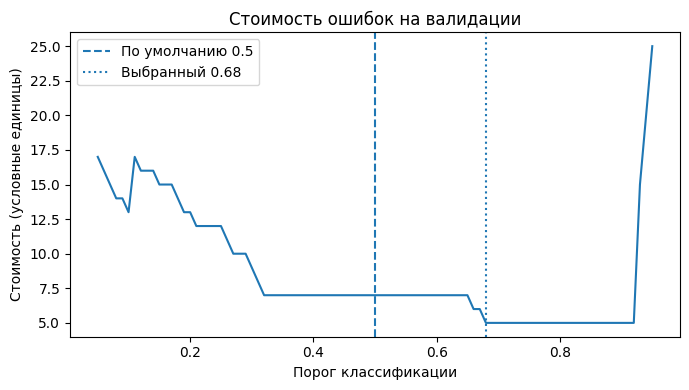

In [2]:
model=Pipeline([('scale',StandardScaler()),('logreg',LogisticRegression(max_iter=3000,random_state=42))])
model.fit(Xtr,ytr)
val_p=model.predict_proba(Xval)[:,1]
# Выбираем порог исключительно по ВАЛИДАЦИИ, не тесту!
thresholds=np.linspace(.05,.95,91)
C_FN,C_FP=5,1
def error_cost(y_true,p,thr):
    cm=confusion_matrix(y_true,(p>=thr).astype(int),labels=[0,1])
    tn,fp,fn,tp=cm.ravel()
    return int(C_FP*fp+C_FN*fn)
val_table=pd.DataFrame({'threshold':thresholds,'cost':[error_cost(yval,val_p,t) for t in thresholds]})
best=val_table.loc[val_table['cost'].idxmin()]
chosen=float(best['threshold'])
print(f'Оптимальный порог по цене ошибок на validation = {chosen:.2f}; cost={int(best["cost"])}')
assert abs(chosen-.5)>1e-10, 'По данным и стоимости выбран порог 0.5; нужна дополнительная проверка постановки задачи.'
fig,ax=plt.subplots(figsize=(7,4));ax.plot(val_table.threshold,val_table.cost)
ax.axvline(.5,ls='--',label='По умолчанию 0.5');ax.axvline(chosen,ls=':',label=f'Выбранный {chosen:.2f}')
ax.set(title='Стоимость ошибок на валидации',xlabel='Порог классификации',ylabel='Стоимость (условные единицы)');ax.legend()
fig.tight_layout();fig.savefig(FIG/'cost_by_threshold.png',dpi=130);plt.show()

## ROC- и PR-кривые на test

Показатели ROC-AUC и AP оценивают способность ранжировать объекты по вероятности и не зависят от выбранного порога. Тест не использован для подбора порога.

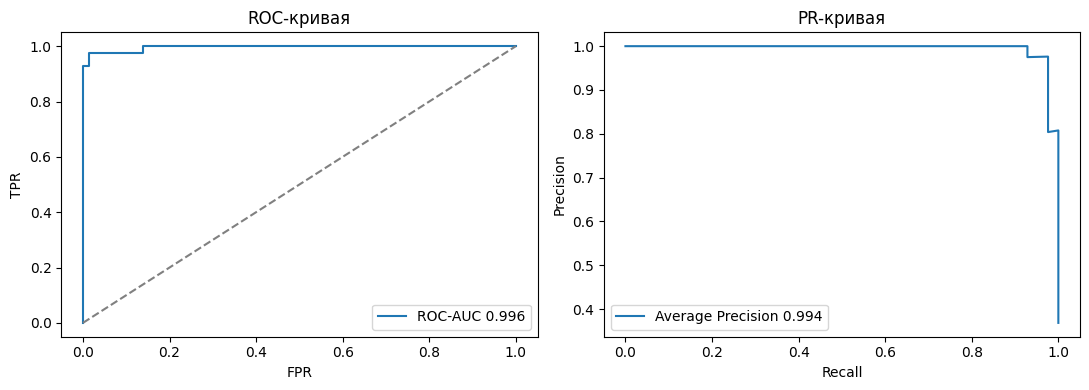

ROC-AUC = 0.996; AP (площадь под PR как средняя точность) = 0.994


In [3]:
# Последний раз обучаем на train+validation, используя тот же набор параметров
model.fit(Xdev,ydev)
p_test=model.predict_proba(Xte)[:,1]
fpr,tpr,_=roc_curve(yte,p_test);pr,re,_=precision_recall_curve(yte,p_test)
roc=roc_auc_score(yte,p_test);ap=average_precision_score(yte,p_test)
fig,axs=plt.subplots(1,2,figsize=(11,4))
axs[0].plot(fpr,tpr,label=f'ROC-AUC {roc:.3f}');axs[0].plot([0,1],[0,1],'--',color='gray')
axs[0].set(title='ROC-кривая',xlabel='FPR',ylabel='TPR');axs[0].legend()
axs[1].plot(re,pr,label=f'Average Precision {ap:.3f}')
axs[1].set(title='PR-кривая',xlabel='Recall',ylabel='Precision');axs[1].legend()
fig.tight_layout();fig.savefig(FIG/'roc_pr.png',dpi=130);plt.show()
print(f'ROC-AUC = {roc:.3f}; AP (площадь под PR как средняя точность) = {ap:.3f}')

## Сравнение при пороге 0.5 и при выбранном пороге

,threshold,accuracy,precision,recall,F1,FP,FN,cost
0,0.50,0.965,0.975,0.929,0.951,1,3,16
1,0.68,0.965,1.000,0.905,0.950,0,4,20


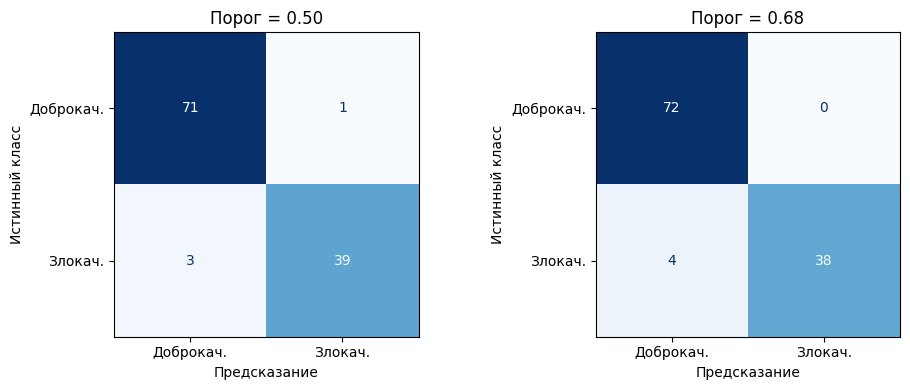

In [4]:
rows=[]
for thr in [.5,chosen]:
    pred=(p_test>=thr).astype(int)
    tn,fp,fn,tp=confusion_matrix(yte,pred,labels=[0,1]).ravel()
    rows.append({'threshold':round(thr,3),'accuracy':accuracy_score(yte,pred),'precision':precision_score(yte,pred,zero_division=0),'recall':recall_score(yte,pred,zero_division=0),'F1':f1_score(yte,pred,zero_division=0),'FP':int(fp),'FN':int(fn),'cost':int(C_FP*fp+C_FN*fn)})
metrics=pd.DataFrame(rows)
display(metrics.round(3))
fig,axs=plt.subplots(1,2,figsize=(10,4))
for ax,thr in zip(axs,[.5,chosen]):
    ConfusionMatrixDisplay.from_predictions(yte,(p_test>=thr).astype(int),display_labels=['Доброкач.','Злокач.'],ax=ax,colorbar=False,cmap='Blues')
    ax.set(title=f'Порог = {thr:.2f}',xlabel='Предсказание',ylabel='Истинный класс')
fig.tight_layout();fig.savefig(FIG/'confusion_matrices.png',dpi=120);plt.show()
Path('../reports').mkdir(exist_ok=True);metrics.to_csv('../reports/metrics.csv',index=False)

## Вывод

In [5]:
a,b=metrics.iloc[0],metrics.iloc[1]
print(f'При FN=5 и FP=1 порог {chosen:.2f} выбран по validation, а не по test.')
print(f'На тесте стоимость ошибок: {a.cost} при 0.5 и {b.cost} при {chosen:.2f}.')
print(f'Recall: {a.recall:.3f} → {b.recall:.3f}; Precision: {a.precision:.3f} → {b.precision:.3f}.')
print('Повышение recall часто требует компромисса с precision; при иной цене ошибок порог следует выбирать заново.')
if b.cost > a.cost:
    print('Важно: выбранный на validation порог НА ТЕСТЕ увеличил стоимость ошибок — это ограничение обобщения; нельзя подбирать порог повторно по test.')
elif b.cost < a.cost:
    print('На тесте выбранный порог снизил суммарную условную стоимость ошибок.')
else:
    print('На тесте суммарная условная стоимость ошибок не изменилась.')
print('Цены ошибок условные учебные, не клинические.')

При FN=5 и FP=1 порог 0.68 выбран по validation, а не по test.
На тесте стоимость ошибок: 16.0 при 0.5 и 20.0 при 0.68.
Recall: 0.929 → 0.905; Precision: 0.975 → 1.000.
Повышение recall часто требует компромисса с precision; при иной цене ошибок порог следует выбирать заново.
Важно: выбранный на validation порог НА ТЕСТЕ увеличил стоимость ошибок — это ограничение обобщения; нельзя подбирать порог повторно по test.
Цены ошибок условные учебные, не клинические.
